# ML Classification
**ResolveX - M3: Label review, training and evaluation**

This notebook trains a TF-IDF + Logistic Regression classifier using question titles and bodies. It covers label review, duplicate-aware splitting, model comparison, confidence calibration and final evaluation.

Categories come from Ask Ubuntu tags and are treated as weak labels: they may be incorrect or ambiguous.

## 1. Load the prepared data

Load the 177,194 single-category candidates prepared in M2. Combine Title and BodyText as model input; keep Tags as metadata only.

In [1]:
from pathlib import Path
import sys
import pandas as pd

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src/data/preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook within ResolveX")
sys.path.insert(0, str(ROOT))
from src.models.classification import load_dataset, sample_label_review, make_splits, audit_near_duplicates, build_pipeline, score_predictions, fit_cached, validation_roles, fit_temperature, confidence_metrics, choose_review_threshold, predict_ticket, sample_multicategory

frame = load_dataset(ROOT / "data/processed/ml_dataset.csv")
print("Candidate questions:", len(frame))

Candidate questions: 177194


## 2. Select a review sample

Select five questions per category with seed 42, giving 30 questions to review before splitting or training. This small sample helps identify labeling problems; it cannot measure their frequency across the full dataset.

In [2]:
review = sample_label_review(frame)
review["ReviewStatus"] = "pending"
review["SuggestedLabel"] = ""
review["ReviewNotes"] = ""
display(review.groupby("Label").size().rename("Review questions").to_frame())
display(review[["Id", "Title", "Label", "ReviewStatus"]])

,Review questions
Label,
Access & Permissions,5
Boot & Startup,5
Hardware & Drivers,5
Network & Connectivity,5
Software & Packages,5
Storage & Filesystems,5


,Id,Title,Label,ReviewStatus
0,259177,problem sharing printer via samba in Ubuntu se...,Access & Permissions,pending
1,474959,Allow ftp permissions for every directory,Access & Permissions,pending
2,1402774,"If user is not in /etc/passwd, can he list the...",Access & Permissions,pending
3,1452650,Trouble using pg_restore or psql or pgAdmin4 t...,Access & Permissions,pending
4,723656,How to disable user's login without disabling ...,Access & Permissions,pending
5,788330,Can't Hibernate or Suspend with Gnome or Unity,Boot & Startup,pending
6,1301330,Unable to shutdown or reboot ubuntu 20.04,Boot & Startup,pending
7,206119,Can't Find Windows's partitions in Linux,Boot & Startup,pending
8,266509,Boot issues with Windows 8 and Ubuntu 12.10 - ...,Boot & Startup,pending
9,356131,Can't boot up Ubuntu after changing grub file ...,Boot & Startup,pending


## 3. Read the sampled questions

The review used the full title and body of all 30 questions. The cell below displays one category at a time; change `CATEGORY` to read another.

Compare the label with the main support request, rather than an incidental tag or a possible root cause.

In [3]:
CATEGORY = "Access & Permissions"
for row in review.loc[review["Label"].eq(CATEGORY)].itertuples():
    print(f"\nQuestion {row.Id}\nTitle: {row.Title}\n\n{row.BodyText}\n\nWeak label: {row.Label}\n")


Question 259177
Title: problem sharing printer via samba in Ubuntu server 12.04

I have cannon ImageRunner 1133 I want to share it through samba with cups server installed on Ubuntu server 12.04 



it works all fine I installed samba and cups server  ubuntu and windows clients can successfully print via samba but I want every user when they click the share printer they should be prompted for username and password for this I have edited smb.conf file and set guest ok = no under printers it works for Ubuntu clients but when windows 7 clients click on the share printer it does not prompt for username and password

Weak label: Access & Permissions


Question 474959
Title: Allow ftp permissions for every directory

I have a computer that I set up with Ubuntu but I don't have a monitor for it so it is a hassle when I need to change something in the file system because I have to unplug a monitor from one of my computers and plug it into my server. I have vsftpd installed on my Ubuntu Server

## 4. Record review decisions

The decisions below are AI-assisted, with a short reason for each question:

- **consistent:** the label fits the main issue.
- **ambiguous:** the issue overlaps categories or is unclear.
- **likely incorrect:** the label does not appear to fit.

Suggested labels are review notes and are not applied to the source data.

In [4]:
review_decisions = {
    '259177': ('consistent', '', 'Printer sharing already works; the requested change is username/password authentication.'),
    '474959': ('consistent', '', 'FTP directory edits fail with permission denied; access rights are the main issue.'),
    '1402774': ('consistent', '', 'UID/GID access to /root inside a container is a permissions issue. Scope caveat: the supplied container image is CentOS, not Ubuntu.'),
    '1452650': ('ambiguous', '', 'Database restoration combines dump format, missing database, file paths and Unix permissions; no single primary category is established.'),
    '723656': ('consistent', '', 'The requested behavior concerns account login restrictions.'),
    '788330': ('ambiguous', '', 'Suspend/hibernate resume restarts the machine; overlaps system startup and hardware power management.'),
    '1301330': ('consistent', '', 'Shutdown and reboot hang; boot/restart lifecycle is the main reported problem, without an established hardware cause.'),
    '206119': ('likely incorrect', 'Storage & Filesystems', 'The request is to access Windows partitions from Ubuntu; dual-boot is context, not the failure.'),
    '266509': ('consistent', '', 'OS selection, UEFI/legacy mode, signatures and BIOS access are directly boot-related.'),
    '356131': ('consistent', '', 'Ubuntu no longer boots after editing GRUB; the immediate support problem is boot recovery.'),
    '443782': ('consistent', '', 'Display configuration disabled both monitors; restoring display settings fits the display/graphics category.'),
    '765435': ('consistent', '', 'Simultaneous integrated/discrete GPU and dual-monitor support is a graphics/driver configuration issue.'),
    '71489': ('consistent', '', 'Sound-card/output detection and drivers are the stated issue.'),
    '827878': ('consistent', '', 'The request is to identify suitable graphics drivers and display settings.'),
    '642001': ('consistent', '', 'The touchpad is missing from input devices and settings; device/driver support is central.'),
    '1113012': ('ambiguous', '', "Local file operations slowed down after a move; internet speed is only the author's suspected cause, not established evidence."),
    '1375619': ('consistent', '', 'The question concerns network clock synchronization between two computers using chrony/NTP.'),
    '1385156': ('consistent', '', 'The wired Ethernet connection cannot be re-enabled after disconnection.'),
    '1108312': ('consistent', '', 'Bonded network interfaces have no internet access; connection configuration is the primary issue.'),
    '239904': ('consistent', '', 'Wireless throughput/connectivity is intermittent despite good reception; a driver cause is possible but unconfirmed.'),
    '1012096': ('ambiguous', '', 'dpkg update failure includes Structure needs cleaning; package failure may be caused by an underlying filesystem problem.'),
    '31397': ('likely incorrect', '', 'Asks whether app-store ratings require a written review; this is a product-feature question, not package installation or maintenance. No replacement class is forced.'),
    '389222': ('consistent', '', 'Broken packages prevent downloading packages and opening Software Center.'),
    '912094': ('consistent', '', 'Composer installation is blocked by missing PHP extensions/dependencies.'),
    '702988': ('consistent', '', 'Installing a deb package fails because a required dependency is absent; hostname warning is incidental.'),
    '356372': ('ambiguous', '', 'The underlying goal is password recovery, but the explicit question is data safety when remounting root; access and filesystem concerns overlap.'),
    '1421868': ('consistent', '', 'Multi-drive partitioning, LVM and disk encryption layout are the primary configuration concerns.'),
    '1293967': ('consistent', '', 'The question concerns swap exhaustion/disablement; swap is explicitly included in the current storage taxonomy. Memory-performance overlap remains a scope caveat.'),
    '621903': ('consistent', '', 'Partition mounting through fstab and its visibility in the file manager are central.'),
    '514748': ('likely incorrect', '', 'The question asks for shell-redirection and /dev/null semantics, not a storage failure. No supported replacement class is sufficiently justified.'),
}
assert set(review_decisions) == set(review["Id"]), "Review sample changed; reassess decisions."
review[["ReviewStatus", "SuggestedLabel", "ReviewNotes"]] = pd.DataFrame(
    review["Id"].map(review_decisions).tolist(), index=review.index
)
display(pd.crosstab(review["Label"], review["ReviewStatus"]))
with pd.option_context("display.max_colwidth", 160):
    display(review[["Id", "Label", "ReviewStatus", "SuggestedLabel", "ReviewNotes"]])
assert not review["ReviewStatus"].eq("pending").any()

ReviewStatus,ambiguous,consistent,likely incorrect
Label,,,
Access & Permissions,1,4,0
Boot & Startup,1,3,1
Hardware & Drivers,0,5,0
Network & Connectivity,1,4,0
Software & Packages,1,3,1
Storage & Filesystems,1,3,1


,Id,Label,ReviewStatus,SuggestedLabel,ReviewNotes
0,259177,Access & Permissions,consistent,,Printer sharing already works; the requested change is username/password authentication.
1,474959,Access & Permissions,consistent,,FTP directory edits fail with permission denied; access rights are the main issue.
2,1402774,Access & Permissions,consistent,,"UID/GID access to /root inside a container is a permissions issue. Scope caveat: the supplied container image is CentOS, not Ubuntu."
3,1452650,Access & Permissions,ambiguous,,"Database restoration combines dump format, missing database, file paths and Unix permissions; no single primary category is established."
4,723656,Access & Permissions,consistent,,The requested behavior concerns account login restrictions.
5,788330,Boot & Startup,ambiguous,,Suspend/hibernate resume restarts the machine; overlaps system startup and hardware power management.
6,1301330,Boot & Startup,consistent,,"Shutdown and reboot hang; boot/restart lifecycle is the main reported problem, without an established hardware cause."
7,206119,Boot & Startup,likely incorrect,Storage & Filesystems,"The request is to access Windows partitions from Ubuntu; dual-boot is context, not the failure."
8,266509,Boot & Startup,consistent,,"OS selection, UEFI/legacy mode, signatures and BIOS access are directly boot-related."
9,356131,Boot & Startup,consistent,,Ubuntu no longer boots after editing GRUB; the immediate support problem is boot recovery.


## Label review findings

The sample contains **22 consistent**, **5 ambiguous** and **3 likely incorrect** labels.

- Exclude the eight ambiguous or likely incorrect questions from training, validation and test.
- Reserve all reviewed duplicate groups for training, with those eight questions excluded. This keeps review-based decisions away from evaluation data.
- Keep the M2 datasets and taxonomy unchanged.

The remaining dataset still has weak labels; reviewing 30 questions does not verify the whole corpus.

## 5. Create duplicate-aware splits

Keep connected duplicate questions in the same split. Use all duplicate links, including intermediate question IDs outside the ML dataset. Also group identical normalized text and identical normalized titles of at least 30 characters; the title rule is a conservative precaution.

Build groups before excluding the eight review cases so their links are preserved. Keep reviewed groups in training, then split the remaining groups with seed 42 and a 70/15/15 target. Actual row proportions depend on group sizes.

In [5]:
reviewed_ids = set(review["Id"])
excluded_ids = set(review.loc[review["ReviewStatus"].ne("consistent"), "Id"])
assignments = make_splits(
    frame, ROOT / "data/processed/duplicate_relationships.csv",
    reviewed_ids=reviewed_ids, excluded_ids=excluded_ids,
)
active = assignments["Split"].ne("excluded")
assert assignments.loc[active].groupby("GroupId")["Split"].nunique().max() == 1
assert assignments.loc[assignments["Id"].isin(reviewed_ids - excluded_ids), "Split"].eq("train").all()
assert set(assignments.loc[assignments["Split"].eq("excluded"), "Id"]) == excluded_ids
repeat = make_splits(frame, ROOT / "data/processed/duplicate_relationships.csv", reviewed_ids=reviewed_ids, excluded_ids=excluded_ids)
assert assignments.equals(repeat), "Split is not reproducible"
assignments.to_csv(ROOT / "data/processed/classification_splits.csv", index=False)
counts = assignments["Split"].value_counts().to_frame("Questions")
counts["Share of active rows"] = counts["Questions"] / int(active.sum())
counts.loc["excluded", "Share of active rows"] = float("nan")
display(counts)
display(pd.crosstab(frame["Label"], assignments["Split"]))
print("Active groups crossing splits: 0")
print("Reviewed groups outside training: 0")
print("Excluded reviewed rows:", len(excluded_ids))

,Questions,Share of active rows
Split,,
train,127403,0.719035
validation,24930,0.140700
test,24853,0.140265
excluded,8,NaN


Split,excluded,test,train,validation
Label,,,,
Access & Permissions,1,2124,10577,2134
Boot & Startup,2,3660,19642,3744
Hardware & Drivers,0,6439,30863,6475
Network & Connectivity,1,4476,21213,4417
Software & Packages,2,5646,32253,5684
Storage & Filesystems,2,2508,12855,2476


Active groups crossing splits: 0
Reviewed groups outside training: 0
Excluded reviewed rows: 8


## 6. Check for near-duplicate text

Sample 100 queries for each split pair and compare them with texts in the other split. Use hashed word and word-pair features, which do not learn a vocabulary. This check uses no labels or classifier predictions.

Flag cosine similarity of 0.95 or higher for inspection. This is a text-similarity screening value, separate from classifier confidence. The sampled check cannot find every semantic duplicate.

In [6]:
near_matches = audit_near_duplicates(frame, assignments)
display(near_matches.groupby(["QuerySplit", "TargetSplit"])["Similarity"].agg(["count", "max"]))
with pd.option_context("display.max_colwidth", 100):
    display(near_matches.head(10))
flagged = near_matches.loc[near_matches["Similarity"].ge(0.95)]
print("Sampled high-similarity pairs:", len(flagged))
if not flagged.empty:
    display(flagged)
    print("Inspect flagged text before treating split preparation as complete.")

count       max
QuerySplit TargetSplit                 
test       train          100  0.915723
           validation     100  0.924248
validation train          100  0.748948

,QueryId,TargetId,QuerySplit,TargetSplit,Similarity,QueryTitle,TargetTitle
0,366952,392266,test,validation,0.924248,Force ntfs volumes to be treated like any other by default,why is the partition not accessible?
1,366952,752786,test,train,0.915723,Force ntfs volumes to be treated like any other by default,Problem with opening USB flash drive stick
2,369785,449341,test,train,0.900075,Accidental running of do-release-upgrade,I can't start the upgrade form 13.10 to 14.04
3,630496,810855,test,train,0.835959,How/where to report missing packages,Failed to fetch packages
4,812196,1478023,test,train,0.809474,Tune Dual Boot with Windows 10 on separate drives,"How to run boot repair when Ubuntu is inaccessible, and conflicts in BIOS settings? (Dual Booting)"
5,369785,131775,test,validation,0.781120,Accidental running of do-release-upgrade,Can't add repos after upgrading to 12.04 LTS
6,1183760,1208307,test,train,0.772434,is my partitioning scheme wrong?,Whole memory eaten on sda7
7,1183760,1402994,test,validation,0.771181,is my partitioning scheme wrong?,Why my root partition is 94% used?
8,1462197,1441810,validation,train,0.748948,"Whenever i'm Trying to install any package I'm getting ""E: Sub-process /usr/bin/dpkg returned an...",getting an error from apt-get autoremove
9,770551,1285502,validation,train,0.744565,Ubuntu 16.04 - NVidia GTX 860M and OpenGL SL 4.5?,glxinfo shows different versions in the same machine on different runs


Sampled high-similarity pairs: 0


## Split findings

- **127,403 train**, **24,930 validation** and **24,853 test** questions; eight review cases are excluded.
- All six categories appear in each active split. Reviewed groups stay in training, and duplicate groups and exact text/title matches do not cross active splits.
- Repeating the split gives the same assignments.
- The near-duplicate check made 300 nearest-neighbor comparisons. Maximum similarity was **0.9242**, below the 0.95 screening value.
- The closest pairs shared mount output or repository-list text but described different requests, so they were not merged.

Test text was used only to check for leakage at this stage; no test predictions or scores were used.

## 7. Train and compare the baseline models

Fit TF-IDF and Logistic Regression on training data only, using Title + BodyText. Start with word unigrams and bigrams, up to 50,000 features and C=1.

Compare ordinary and balanced Logistic Regression with a majority-class reference. Evaluate this comparison on validation data.

In [7]:
import time
import numpy as np
import joblib
import sklearn
from scipy.special import softmax

train = frame.loc[assignments["Split"].eq("train")]
validation = frame.loc[assignments["Split"].eq("validation")]
print("scikit-learn:", sklearn.__version__)
majority = train["Label"].value_counts().idxmax()
results = [{"Model": "Majority class", **score_predictions(validation["Label"], np.repeat(majority, len(validation)))}]
models = {}
for name, weight in [("Logistic Regression", None), ("Balanced Logistic Regression", "balanced")]:
    started = time.perf_counter()
    filename = "baseline_balanced.joblib" if weight else "baseline_unweighted.joblib"
    pipeline, action = fit_cached(train, ROOT / "data/processed" / filename, class_weight=weight)
    prediction = pipeline.predict(validation["Text"])
    results.append({"Model": name, **score_predictions(validation["Label"], prediction)})
    models[name] = pipeline
    print(name, action, "iterations:", pipeline.named_steps["classifier"].n_iter_, "seconds:", round(time.perf_counter()-started, 1), flush=True)
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))
comparison.to_csv(ROOT / "data/processed/classification_validation_metrics.csv")
print("Test predictions computed so far: 0")

scikit-learn: 1.9.0


Logistic Regression loaded matching cache iterations: [105] seconds: 8.6


Balanced Logistic Regression loaded matching cache iterations: [147] seconds: 7.5


,Accuracy,Macro F1,Weighted F1
Model,,,
Majority class,0.2280,0.0619,0.0847
Logistic Regression,0.8982,0.8864,0.8980
Balanced Logistic Regression,0.8953,0.8832,0.8958


Test predictions computed so far: 0


## Baseline findings

- Ordinary Logistic Regression reaches validation Accuracy **0.8982**, Macro F1 **0.8864** and Weighted F1 **0.8980**. The majority reference reaches Accuracy **0.2280** and Macro F1 **0.0619**.
- Balanced class weights give Macro F1 **0.8832**. Continue with the ordinary model, which performs better in this comparison.
- Both models converged: 105 iterations for ordinary and 147 for balanced Logistic Regression. Both were fitted on training rows only.

The word-based tokenizer may miss distinctions carried by command punctuation. These are development results against weak labels; final test evaluation comes later.

## 8. Assign validation roles

Divide validation groups into three separate roles: choosing model settings (40%), calibrating confidence (30%) and selecting the review threshold (30%). These percentages refer to groups; actual question counts are shown below.

The earlier baseline comparison used the full validation set, so all three roles remain development data. The test set stays separate.

In [8]:
roles = validation_roles(assignments)
assignments["ValidationRole"] = roles
assignments.to_csv(ROOT / "data/processed/classification_splits.csv", index=False)
selection = frame.loc[roles.eq("selection")]
calibration = frame.loc[roles.eq("calibration")]
policy_data = frame.loc[roles.eq("policy")]
for subset in (selection, calibration, policy_data):
    assert set(subset["Label"]) == set(train["Label"])
display(roles.loc[roles.ne("")].value_counts().to_frame("Questions"))
assert not roles.loc[assignments["Split"].eq("test")].ne("").any()

,Questions
ValidationRole,
selection,9969
calibration,7517
policy,7444


## 9. Choose the model setting

Compare C = 0.5, 1 and 2 for the ordinary classifier, keeping the training data and TF-IDF settings fixed. Choose the highest selection-set Macro F1; prefer smaller C if scores tie.

This is a small search. Reuse a saved experiment only when its training data, settings, code and scikit-learn version match.

In [9]:
candidates = {1.0: models["Logistic Regression"]}
setting_results = []
for value in (0.5, 1.0, 2.0):
    if value not in candidates:
        filename = "classification_C" + str(value).replace(".", "p") + ".joblib"
        started = time.perf_counter()
        candidates[value], action = fit_cached(train, ROOT / "data/processed" / filename, C=value)
        print("C =", value, action, "seconds:", round(time.perf_counter()-started, 1), flush=True)
    prediction = candidates[value].predict(selection["Text"])
    setting_results.append({"C": value, **score_predictions(selection["Label"], prediction)})
setting_comparison = pd.DataFrame(setting_results).sort_values(["Macro F1", "C"], ascending=[False, True])
display(setting_comparison.round(4))
selected_C = float(setting_comparison.iloc[0]["C"])
selected = candidates[selected_C]
print("Selected C:", selected_C)
classes = selected.classes_

C = 0.5 loaded matching cache seconds: 1.3


C = 2.0 loaded matching cache seconds: 1.2


,C,Accuracy,Macro F1,Weighted F1
1,1.0,0.8978,0.8862,0.8976
2,2.0,0.8970,0.8851,0.8968
0,0.5,0.8963,0.8845,0.8960


Selected C: 1.0


## 10. Inspect prediction disagreements

Show the most common confusion pairs and two high-confidence disagreements per label from the selection set. Read the texts to distinguish possible model mistakes, noisy labels and category overlap. Keep validation labels unchanged.

In [10]:
selection_logits = selected.decision_function(selection["Text"])
selection_probabilities = softmax(selection_logits, axis=1)
selection_predictions = classes[selection_probabilities.argmax(axis=1)]
errors = selection[["Id", "Title", "BodyText", "Label"]].copy()
errors["Prediction"] = selection_predictions
errors["RawConfidence"] = selection_probabilities.max(axis=1)
errors = errors.loc[errors["Label"].ne(errors["Prediction"])]
confusions = errors.groupby(["Label", "Prediction"]).size().sort_values(ascending=False).head(10)
display(confusions.rename("Disagreements").to_frame())
error_sample = errors.sort_values("RawConfidence", ascending=False).groupby("Label", sort=True).head(2)
error_sample["BodyPreview"] = error_sample["BodyText"].str.slice(0, 350)
with pd.option_context("display.max_colwidth", 120):
    display(error_sample[["Id", "Title", "Label", "Prediction", "RawConfidence", "BodyPreview"]])

,,Disagreements
Label,Prediction,
Hardware & Drivers,Software & Packages,81
Boot & Startup,Software & Packages,73
Software & Packages,Hardware & Drivers,61
Boot & Startup,Hardware & Drivers,60
Network & Connectivity,Hardware & Drivers,49
Boot & Startup,Storage & Filesystems,47
Software & Packages,Boot & Startup,45
Storage & Filesystems,Boot & Startup,45
Access & Permissions,Software & Packages,43


,Id,Title,Label,Prediction,RawConfidence,BodyPreview
112049,1034553,systemd resolve doesn't respond to queries,Boot & Startup,Network & Connectivity,0.999231,I'm getting dns failures on some of the servers with Ubuntu Server 17.10 or 18.01. I can't resolve addresses unless ...
160450,1401663,Connected to wifi network but no internet after updating ubuntu to 20.04,Software & Packages,Network & Connectivity,0.997451,I just updated ubuntu to 20.04 and now my wifi isnt working even though it is on my other windows machine. Ive also ...
4949,49371,fstab folder bind on partition mounted with defaults parameter,Access & Permissions,Storage & Filesystems,0.997194,I want bind some folders in my Home directory with some folders in a NTFS partition. Will mounting the NTFS partitio...
11434,115072,How to install Ubuntu on Acer 4752?,Software & Packages,Hardware & Drivers,0.994633,"How to install ubuntu on my Laptop??\n\n\n\nI'm trying to install ubuntu ""ubuntu-11.10-desktop-i386"" on my laptop.. ..."
166890,1445435,Linux TCP/IP Connections Limit,Hardware & Drivers,Network & Connectivity,0.993085,"I want only 1 incoming connection from port 1000 to 65535 to be able to connect to the ubuntu server, how and in wha..."
160219,1399922,downloading graphics.h,Hardware & Drivers,Software & Packages,0.989785,"I'm trying to download graphics.h, but when I get to the part where I have to extract the libgraph-1.0.2.tar.gz file..."
14319,143341,How to upgrade Ubuntu 11.10 to Ubuntu 12.04 using Wubi ISO,Boot & Startup,Software & Packages,0.989312,"I have downloaded, Ubuntu 12.04 ISO Wubi installer ISO I believe. I have Ubuntu 11.10. I want to know how to upgrade..."
127711,1161092,How play music with Ubuntu 18.04 using Airplay?,Network & Connectivity,Hardware & Drivers,0.983218,"Like on Macintosh (or even Windows, I suppose), iTunes will immediately recognize and use wireless streaming to play..."
84298,809609,Unable to Remote Login a Ubuntu Router via OpenSSH with Successful Ping Result,Access & Permissions,Network & Connectivity,0.975885,"I want to remotely login a Ubuntu Router via OpenSSH but when I type the following to login, I cannot get back any r..."
27342,269643,How do I map users with a samba share?,Storage & Filesystems,Access & Permissions,0.973793,I have a Synology Diskstation with a published windows share.\nOn both the server and the client (Ubuntu 12.04) I ha...


### Disagreement review

The full texts of the 12 displayed examples were inspected with AI assistance. These high-confidence disagreements were selected deliberately, so they are not a representative error sample or corrected ground truth.

| ID | Interpretation |
| --- | --- |
| 1034553 | DNS resolution is the main failure. Network is plausible despite the systemd-related Boot label. |
| 1401663 | Connectivity fails after an upgrade. Network fits the issue; Software reflects the upgrade context. |
| 49371 | NTFS bind mounts and read/write permissions overlap Storage and Access. |
| 115072 | Ubuntu installation question. Hardware details may have distracted the model into Hardware: a likely model mistake. |
| 1445435 | Restricting incoming TCP connections fits Network more plausibly than Hardware. |
| 1399922 | Installing graphics.h/libgraph concerns software dependencies rather than a graphics-device fault. |
| 143341 | Ubuntu upgrade via Wubi. Software is plausible; GRUB is part of the context. |
| 1161092 | AirPlay streaming and sound output overlap Network and Hardware/audio. |
| 809609 | SSH timeout overlaps networking and remote access; an authentication failure is not established. |
| 269643 | UID mapping and share permissions make Access plausible despite the mount context. |
| 108844 | The recovery loader restarts instead of opening recovery. Boot is plausible despite a partition-related label. |
| 486824 | Missing Skype package archive. Software is plausible despite networking context. |

The sample contains noisy labels, overlapping issues and a likely model mistake. Keep the baseline and taxonomy unchanged for this experiment.

## 11. Calibrate confidence and choose a review threshold

Fit one temperature on the calibration subset by minimizing negative log-likelihood (NLL). This adjusts confidence without changing the predicted category. Keep it if NLL also improves on the policy subset; otherwise use temperature 1. Report ECE using 10 equal-width confidence bins.

On the policy subset, choose the threshold that retains the most questions while reaching at least **95% agreement with weak labels**, with at least **200 retained examples**. Handle equal confidence values together. Questions below the threshold are flagged for review, without adding an Other category.

The 95% target is a prototype operating choice, not a guarantee of technical correctness or future performance.

,NLL,Brier,ECE
Variant,,,
Raw,0.3369,0.1627,0.0412
Temperature-scaled,0.3232,0.1584,0.0181


Learned temperature: 0.8000662155523415 Retained: 0.8000662155523415
Review policy: {'threshold': 0.7492341336823973, 'target_agreement': 0.95, 'min_accepted': 200, 'accepted': 6222, 'coverage': 0.8358409457281032, 'agreement': 0.9500160720025715}


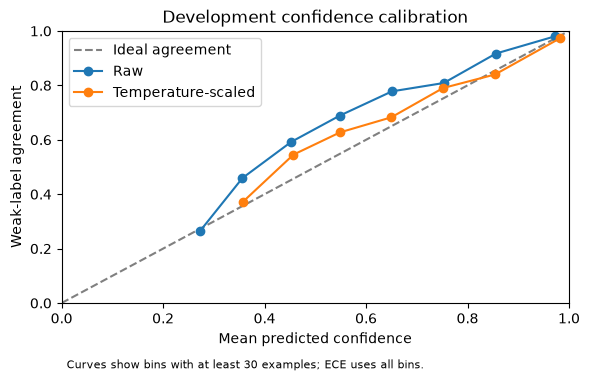

In [11]:
calibration_logits = selected.decision_function(calibration["Text"])
learned_temperature = fit_temperature(calibration_logits, calibration["Label"], classes)
policy_logits = selected.decision_function(policy_data["Text"])
raw_probabilities = softmax(policy_logits, axis=1)
scaled_probabilities = softmax(policy_logits / learned_temperature, axis=1)
raw_metrics, raw_reliability = confidence_metrics(policy_data["Label"], raw_probabilities, classes)
scaled_metrics, scaled_reliability = confidence_metrics(policy_data["Label"], scaled_probabilities, classes)
temperature = learned_temperature if scaled_metrics["NLL"] < raw_metrics["NLL"] else 1.0
policy_probabilities = softmax(policy_logits / temperature, axis=1)
review_policy = choose_review_threshold(policy_data["Label"], policy_probabilities, classes)
display(pd.DataFrame([{"Variant": "Raw", **raw_metrics}, {"Variant": "Temperature-scaled", **scaled_metrics}]).set_index("Variant").round(4))
print("Learned temperature:", learned_temperature, "Retained:", temperature)
print("Review policy:", review_policy)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Ideal agreement")
for name, points in [("Raw", raw_reliability), ("Temperature-scaled", scaled_reliability)]:
    points = points.loc[points["Count"].ge(30)]
    ax.plot(points["Mean confidence"], points["Weak-label agreement"], marker="o", label=name)
ax.set(xlabel="Mean predicted confidence", ylabel="Weak-label agreement", title="Development confidence calibration", xlim=(0, 1), ylim=(0, 1))
ax.legend()
ax.text(0.01, -0.24, "Curves show bins with at least 30 examples; ECE uses all bins.", transform=ax.transAxes, fontsize=8)
plt.tight_layout()
plt.show()
artifact = {"pipeline": selected, "temperature": temperature, "review_policy": review_policy,
            "metadata": {"C": selected_C, "seed": 42, "sklearn_version": sklearn.__version__, "label_source": "tag-derived weak labels"}}

## 12. Check multi-category questions

Sample 100 multi-category questions outside known duplicate groups containing single-category candidates. Inspect confidence and review frequency without forcing a single reference label. This is a diagnostic check, not a scored single-label test.

In [12]:
multi = sample_multicategory(ROOT / "data/interim/questions.csv", ROOT / "data/processed/duplicate_relationships.csv", frame["Id"])
assert len(multi) == 100
multi_predictions = pd.DataFrame([predict_ticket(artifact, row.Title, row.BodyText) for row in multi.itertuples()])
multi_diagnostics = pd.concat([multi[["Id", "Title", "MatchedCategories"]].reset_index(drop=True), multi_predictions], axis=1)
print("Multi-category sample:", len(multi_diagnostics))
print("Mean confidence:", multi_diagnostics["confidence"].mean())
print("Human-review fraction:", multi_diagnostics["human_review"].mean())
with pd.option_context("display.max_colwidth", 100):
    display(multi_diagnostics.head(10))

Multi-category sample: 100
Mean confidence: 0.8082284446970385
Human-review fraction: 0.32


,Id,Title,MatchedCategories,category,confidence,human_review
0,1005949,Unable to `apt-get` upgrade: How can I replace corrupted `systemd` `.conf` files?,"[Boot & Startup, Software & Packages]",Software & Packages,0.992696,False
1,1200411,Ubuntu 18.04 can't change language at login screen,"[Hardware & Drivers, Access & Permissions]",Access & Permissions,0.661888,True
2,1422970,USB Ethernet device not connecting,"[Network & Connectivity, Hardware & Drivers]",Hardware & Drivers,0.815022,False
3,1074042,Resize disk to Install windows 10 alongside Ubuntu,"[Boot & Startup, Storage & Filesystems]",Storage & Filesystems,0.651390,True
4,1446447,"Installing NVDIA-driver-525 fails, what am I missing?","[Software & Packages, Hardware & Drivers]",Hardware & Drivers,0.997405,False
5,410115,Trouble installing Ubuntu on a secondhand IBM server,"[Boot & Startup, Software & Packages]",Boot & Startup,0.694050,True
6,1047588,Keyboard and mouse not working after boot,"[Software & Packages, Hardware & Drivers]",Hardware & Drivers,0.987829,False
7,524875,Booting from a USB on a PC Syslinux Boot Promt,"[Boot & Startup, Hardware & Drivers]",Boot & Startup,0.994582,False
8,1383178,Resize ubuntu partition after removing windows on dual-boot,"[Boot & Startup, Storage & Filesystems]",Storage & Filesystems,0.951015,False
9,370667,Empty Disk when trying to install dual-boot system,"[Boot & Startup, Storage & Filesystems]",Boot & Startup,0.802967,False


## 13. Try ticket-like examples

Use ten handcrafted examples to inspect clear categories, overlapping issues and unsupported requests. These are illustrations, not real enterprise tickets or training examples.

In [13]:
ticket_examples = [
    ("Network & Connectivity", "Office Wi-Fi keeps disconnecting", "My Ubuntu laptop disconnects from the wireless network every few minutes. Other devices stay connected."),
    ("Boot & Startup", "Ubuntu no longer boots after an update", "The laptop stops at the GRUB menu and never reaches the login screen."),
    ("Software & Packages", "Cannot install a package", "apt reports unmet dependencies and dpkg returns an error when I install software."),
    ("Hardware & Drivers", "External monitor is not detected", "Ubuntu does not recognize the HDMI monitor after installing the NVIDIA graphics driver."),
    ("Storage & Filesystems", "Cannot mount the data partition", "My external NTFS disk cannot be mounted and reports a filesystem error."),
    ("Access & Permissions", "Permission denied opening a shared folder", "My Ubuntu account cannot read the directory, but another user can. Please check ownership and permissions."),
    ("Ambiguous", "Wi-Fi broke after a driver update", "Wireless stopped working after I updated the kernel and installed a new adapter driver."),
    ("Ambiguous", "Computer cannot boot after moving partitions", "I resized the disk partitions and now GRUB cannot find the Ubuntu root filesystem."),
    ("Unsupported", "Payroll reimbursement missing", "My travel expense claim was approved but the reimbursement has not arrived."),
    ("Unsupported", "Coffee machine needs maintenance", "The office coffee machine leaks water and cannot make a drink."),
]
ticket_results = []
for expected, title, body in ticket_examples:
    ticket_results.append({"Scenario": expected, "Title": title, **predict_ticket(artifact, title, body)})
with pd.option_context("display.max_colwidth", 80):
    display(pd.DataFrame(ticket_results))

,Scenario,Title,category,confidence,human_review
0,Network & Connectivity,Office Wi-Fi keeps disconnecting,Network & Connectivity,0.999952,False
1,Boot & Startup,Ubuntu no longer boots after an update,Boot & Startup,0.964452,False
2,Software & Packages,Cannot install a package,Software & Packages,0.999861,False
3,Hardware & Drivers,External monitor is not detected,Hardware & Drivers,0.999902,False
4,Storage & Filesystems,Cannot mount the data partition,Storage & Filesystems,0.999970,False
5,Access & Permissions,Permission denied opening a shared folder,Access & Permissions,0.999776,False
6,Ambiguous,Wi-Fi broke after a driver update,Network & Connectivity,0.895055,False
7,Ambiguous,Computer cannot boot after moving partitions,Boot & Startup,0.879312,False
8,Unsupported,Payroll reimbursement missing,Hardware & Drivers,0.449459,True
9,Unsupported,Coffee machine needs maintenance,Software & Packages,0.379036,True


## Final choices before test evaluation

- **Model:** ordinary Logistic Regression with C=1, which has the highest selection-set Macro F1 among the three settings.
- **Calibration:** temperature **0.800066**. On policy data, NLL improves from 0.3369 to 0.3232 and ECE from 0.0412 to 0.0181.
- **Review threshold:** **0.749234**. It retains 6,222 of 7,444 policy questions (83.6%) with 95.0% weak-label agreement.

The multi-category sample has mean confidence 0.808 and a 32% review rate. The six clear handcrafted examples receive their intended categories. Both overlapping examples receive high-confidence predictions without review flags; both unsupported examples are flagged. These small checks do not establish reliable ambiguity or domain detection.

Model settings, calibration and threshold were fixed before test evaluation. Engineers still review every ticket, including those without an additional review flag.

## 14. Save and reload the classifier

Save the trained pipeline, temperature and review policy together in `data/processed/classifier.joblib`. Include training and split fingerprints and the software version, then check that reloading preserves predictions.

Keep the pipeline fitted on training data only. Refitting after calibration would change the confidence scores used to select the threshold. Generated model files remain local.

In [14]:
import hashlib
import json
artifact["metadata"].update({
    "features": "Title + BodyText only",
    "training_rows": int(len(train)),
    "excluded_review_ids": sorted(excluded_ids),
    "validation_roles": {key: int(value) for key, value in roles[roles.ne("")].value_counts().items()},
    "training_fingerprint": hashlib.sha256(pd.util.hash_pandas_object(train[["Id", "Text", "Label"]], index=False).to_numpy().tobytes()).hexdigest(),
    "split_fingerprint": hashlib.sha256((ROOT / "data/processed/classification_splits.csv").read_bytes()).hexdigest(),
    "development_choices_frozen": True,
})
MODEL_PATH = ROOT / "data/processed/classifier.joblib"
joblib.dump(artifact, MODEL_PATH)
loaded_artifact = joblib.load(MODEL_PATH)
for _, title, body in ticket_examples[:3]:
    assert predict_ticket(artifact, title, body) == predict_ticket(loaded_artifact, title, body)
print("Saved and reloaded classifier:", MODEL_PATH.relative_to(ROOT))
print(predict_ticket(loaded_artifact, "Cannot install software", "apt fails with unmet dependencies"))

Saved and reloaded classifier: data\processed\classifier.joblib
{'category': 'Software & Packages', 'confidence': 0.9996192231524417, 'human_review': False}


## 15. Evaluate on the held-out test set

Evaluate the saved classifier after fixing all development choices. Report classification metrics, per-class results and a confusion matrix against weak labels.

Also report review coverage and agreement for questions without an additional review flag, including per-class differences. Use test results for final reporting, not for adjusting the model or threshold.

All-case held-out scores: {'Accuracy': 0.896833380276023, 'Macro F1': 0.8856166342938848, 'Weighted F1': 0.8966904022986234}
Frozen review-policy results: {'test_rows': 24853, 'accepted': 20774, 'coverage': 0.8358749446746871, 'review_fraction': 0.16412505532531285, 'retained_weak_label_agreement': 0.9539328006161548}


,precision,recall,f1-score,support,Coverage,Retained agreement
Access & Permissions,0.8652,0.8192,0.8416,2124.0,0.7307,0.9137
Boot & Startup,0.8725,0.8579,0.8651,3660.0,0.7814,0.9416
Hardware & Drivers,0.9189,0.9273,0.9231,6439.0,0.8792,0.9613
Network & Connectivity,0.9452,0.9252,0.9351,4476.0,0.8718,0.9698
Software & Packages,0.8800,0.9157,0.8975,5646.0,0.8620,0.9601
Storage & Filesystems,0.8546,0.8481,0.8513,2508.0,0.7703,0.9353


,NLL,Brier,ECE
Variant,,,
Raw,0.3334,0.1600,0.0399
Calibrated,0.3191,0.1556,0.0133


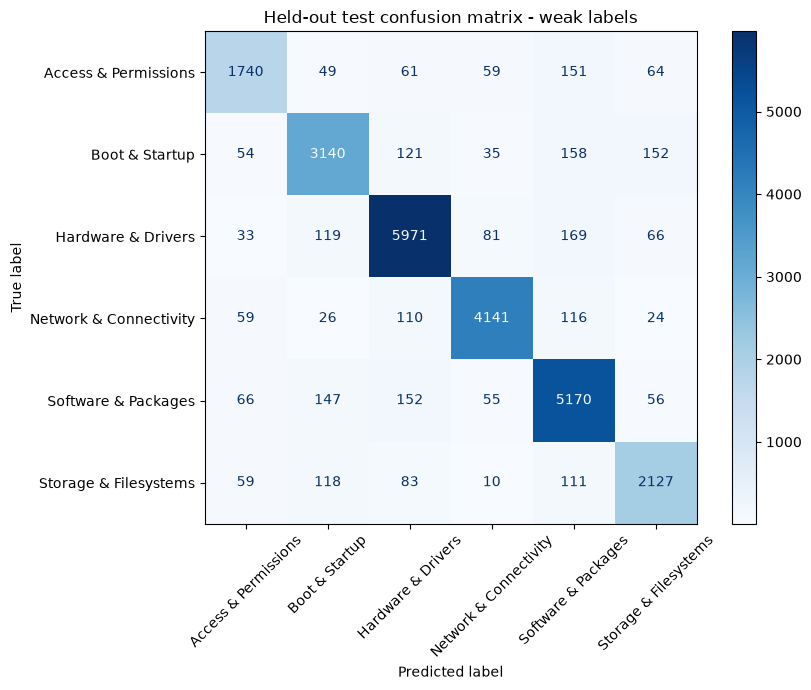

In [15]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

test = frame.loc[assignments["Split"].eq("test")]
test_logits = loaded_artifact["pipeline"].decision_function(test["Text"])
test_probabilities = softmax(test_logits / loaded_artifact["temperature"], axis=1)
test_predictions = classes[test_probabilities.argmax(axis=1)]
test_scores = score_predictions(test["Label"], test_predictions)
threshold = loaded_artifact["review_policy"]["threshold"]
accepted = np.zeros(len(test), dtype=bool) if threshold is None else test_probabilities.max(axis=1) >= threshold
correct = test_predictions == test["Label"].to_numpy()
test_policy = {
    "test_rows": int(len(test)), "accepted": int(accepted.sum()),
    "coverage": float(accepted.mean()), "review_fraction": float(1-accepted.mean()),
    "retained_weak_label_agreement": float(correct[accepted].mean()) if accepted.any() else None,
}
print("All-case held-out scores:", test_scores)
print("Frozen review-policy results:", test_policy)
report = classification_report(test["Label"], test_predictions, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[classes, ["precision", "recall", "f1-score", "support"]]
for label in classes:
    mask = test["Label"].eq(label).to_numpy()
    kept = mask & accepted
    per_class.loc[label, "Coverage"] = float(accepted[mask].mean())
    per_class.loc[label, "Retained agreement"] = float(correct[kept].mean()) if kept.any() else float("nan")
display(per_class.round(4))
raw_test_metrics, _ = confidence_metrics(test["Label"], softmax(test_logits, axis=1), classes)
calibrated_test_metrics, _ = confidence_metrics(test["Label"], test_probabilities, classes)
display(pd.DataFrame([{"Variant": "Raw", **raw_test_metrics}, {"Variant": "Calibrated", **calibrated_test_metrics}]).set_index("Variant").round(4))
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(test["Label"], test_predictions, labels=classes, display_labels=classes, xticks_rotation=45, cmap="Blues", ax=ax)
ax.set_title("Held-out test confusion matrix - weak labels")
plt.tight_layout()
plt.show()
summary = {"classification": test_scores, "review_policy": test_policy,
           "confidence": {"raw": raw_test_metrics, "calibrated": calibrated_test_metrics},
           "C": selected_C, "temperature": temperature, "threshold": threshold,
           "split_fingerprint": loaded_artifact["metadata"]["split_fingerprint"]}
_ = (ROOT / "data/processed/classification_test_metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

## Final results and limitations

**Results**

- On **24,853 test questions**, Accuracy is **89.68%**, Macro F1 **0.8856** and Weighted F1 **0.8967**.
- The fixed threshold retains **20,774 questions (83.6%)** without an additional review flag, with **95.39% weak-label agreement**. The other **16.4%** are flagged.
- Calibration improves test NLL from **0.3334 to 0.3191** and ECE from **0.0399 to 0.0133**. The reliability plot shows bins with at least 30 examples; ECE includes all bins.
- Per-class F1 ranges from **0.8416** for Access & Permissions to **0.9351** for Network & Connectivity. Retained agreement also varies by class; the overall figure is not a per-class guarantee.

**Limitations**

- Results measure agreement with tag-derived labels. The AI-assisted reviews are not independent human annotation.
- This is a grouped random split of historical forum data, not a test of future Ubuntu versions or real enterprise tickets.
- Confidence can miss ambiguous or unsupported requests. Engineers retain final review for every ticket.
- Known duplicates and exact matches were checked; near-duplicate inspection was sampled.

The saved classifier bundles the pipeline, calibration and review policy. `predict_ticket` in `src/models/classification.py` returns a category, confidence and review flag. Keep generated artifacts local and develop future changes without tuning against these test results.